In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 36

In [2]:
cols = ["age","workclass","fnlwgt","education","education_num","marital_status",
        "occupation","relationship","race","sex","capital_gain","capital_loss",
        "hours_per_week","native_country","income"]
base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

train_raw = pd.read_csv(base + "adult.data", names=cols, skipinitialspace=True, na_values="?")
test_raw  = pd.read_csv(base + "adult.test", names=cols, skipinitialspace=True, na_values="?", skiprows=1)

df = pd.concat([train_raw, test_raw], ignore_index=True)
df["income"] = df["income"].str.replace(".", "", regex=False)
print(df.shape)

(48842, 15)


In [3]:
print(df.isna().sum())
df = df.dropna().reset_index(drop=True)
print(df.shape)

age                  0
workclass         2799
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     857
income               0
dtype: int64
(45222, 15)


In [4]:
df["y"] = (df["income"] == ">50K").astype(int)
df = df.drop(columns=["income", "fnlwgt", "education"])
df["native_country"] = np.where(df["native_country"] == "United-States", "US", "Non-US")
print(df["y"].mean())

0.2478439697492371


In [5]:
print(df[["age","capital_gain","capital_loss","hours_per_week"]].describe())
print("capital_gain == 99999:", (df["capital_gain"] == 99999).sum())

df["capital_gain"] = np.log1p(df["capital_gain"])
df["capital_loss"] = np.log1p(df["capital_loss"])

                age  capital_gain  capital_loss  hours_per_week
count  45222.000000  45222.000000  45222.000000    45222.000000
mean      38.547941   1101.430344     88.595418       40.938017
std       13.217870   7506.430084    404.956092       12.007508
min       17.000000      0.000000      0.000000        1.000000
25%       28.000000      0.000000      0.000000       40.000000
50%       37.000000      0.000000      0.000000       40.000000
75%       47.000000      0.000000      0.000000       45.000000
max       90.000000  99999.000000   4356.000000       99.000000
capital_gain == 99999: 229


In [6]:
cat_cols = ["workclass","marital_status","occupation","relationship","race","sex","native_country"]
X = pd.get_dummies(df.drop(columns="y"), columns=cat_cols, drop_first=True, dtype=int)
y = df["y"]
print(X.shape)

(45222, 41)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_train, X_test = X_train.copy(), X_test.copy()

num_cols = ["age","education_num","capital_gain","capital_loss","hours_per_week"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

print(X_train.shape, X_test.shape)

(31655, 41) (13567, 41)


In [8]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score

lin = LinearRegression().fit(X_train, y_train)                                  # Model A (OLS)
logit = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_train, y_train)  # Model B

lin_pred = lin.predict(X_test)
log_prob = logit.predict_proba(X_test)[:, 1]

In [9]:
median_lin = np.median(lin_pred)
flag_A = (lin_pred >= median_lin).astype(int)
flag_B = (log_prob >= 0.5).astype(int)

print("Median of Model A predictions:", round(median_lin, 4))
print("Model A predictions below 0 or above 1:", ((lin_pred < 0) | (lin_pred > 1)).sum())
print("Model A flags high risk:", flag_A.sum(), f"({flag_A.mean()*100:.2f}%)")
print("Model B flags high risk:", flag_B.sum(), f"({flag_B.mean()*100:.2f}%)")

cm = pd.crosstab(pd.Series(flag_A, name="Model A (>= median)"),
                 pd.Series(flag_B, name="Model B (>= 0.5)"))
print(cm)

mismatch = (flag_A != flag_B).sum()
print("Mismatched cases:", mismatch, f"({mismatch/len(flag_A)*100:.2f}%)")

print("Model A accuracy:", round(accuracy_score(y_test, flag_A), 4))
print("Model B accuracy:", round(accuracy_score(y_test, flag_B), 4))

Median of Model A predictions: 0.2313
Model A predictions below 0 or above 1: 2946
Model A flags high risk: 6784 (50.00%)
Model B flags high risk: 2810 (20.71%)
Model B (>= 0.5)        0     1
Model A (>= median)            
0                    6783     0
1                    3974  2810
Mismatched cases: 3974 (29.29%)
Model A accuracy: 0.7169
Model B accuracy: 0.8432


In [10]:
import statsmodels.formula.api as smf

d = df.copy()
d["female"]  = (d["sex"] == "Female").astype(int)
d["married"] = d["marital_status"].isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)

print("Overall >50K rate by sex:")
print(d.groupby("sex")["y"].mean().round(4))
print("\n>50K rate by marital status and sex:")
print(d.groupby(["married", "sex"])["y"].mean().unstack().round(4))
print("\nGroup sizes:")
print(d.groupby(["married", "sex"]).size().unstack())

Overall >50K rate by sex:
sex
Female    0.1136
Male      0.3125
Name: y, dtype: float64

>50K rate by marital status and sex:
sex      Female    Male
married                
0        0.0505  0.0857
1        0.4655  0.4529

Group sizes:
sex      Female   Male
married               
0         12461  11674
1          2234  18853


In [11]:
formula = "y ~ female + age + education_num + hours_per_week"

def fit_report(data, label):
    m = smf.logit(formula, data=data).fit(disp=0)
    ci = m.conf_int()
    return pd.DataFrame({"model": label, "coef": m.params, "ci_low": ci[0],
                         "ci_high": ci[1], "p_value": m.pvalues, "n": len(data)})

results = pd.concat([
    fit_report(d, "Full dataset"),
    fit_report(d[d["married"] == 1], "Subgroup A: married"),
    fit_report(d[d["married"] == 0], "Subgroup B: not married"),
])

print(results.loc["female"].round(4))
print()
print(results.round(4))

                          model    coef  ci_low  ci_high  p_value      n
female             Full dataset -1.1876 -1.2497  -1.1254      0.0  45222
female      Subgroup A: married  0.2877  0.1883   0.3871      0.0  21087
female  Subgroup B: not married -0.7252 -0.8403  -0.6102      0.0  24135

                                  model     coef   ci_low  ci_high  p_value  \
Intercept                  Full dataset  -7.9121  -8.0974  -7.7268      0.0   
female                     Full dataset  -1.1876  -1.2497  -1.1254      0.0   
age                        Full dataset   0.0464   0.0444   0.0484      0.0   
education_num              Full dataset   0.3561   0.3452   0.3671      0.0   
hours_per_week             Full dataset   0.0339   0.0318   0.0361      0.0   
Intercept           Subgroup A: married  -6.2153  -6.4555  -5.9751      0.0   
female              Subgroup A: married   0.2877   0.1883   0.3871      0.0   
age                 Subgroup A: married   0.0252   0.0225   0.0279      0.0

In [12]:
drop_cols = [c for c in X_train.columns
             if c.startswith("marital_status_") or c.startswith("relationship_")]
print("Dropped columns:", drop_cols)

reduced = LogisticRegression(max_iter=2000, random_state=SEED).fit(
    X_train.drop(columns=drop_cols), y_train)

coef_full = pd.Series(logit.coef_[0], index=X_train.columns).drop(drop_cols)
coef_red  = pd.Series(reduced.coef_[0], index=X_train.drop(columns=drop_cols).columns)

ovb = pd.DataFrame({"full": coef_full, "reduced": coef_red})
ovb["change"] = ovb["reduced"] - ovb["full"]
ovb["pct_change"] = ovb["change"] / ovb["full"].abs() * 100

key = ["sex_Male", "age", "education_num", "hours_per_week", "capital_gain"]
print("\nKey predictors:")
print(ovb.loc[key].round(4))

print("\nAll predictors, sorted by size of % change:")
print(ovb.reindex(ovb["pct_change"].abs().sort_values(ascending=False).index).round(4))

print("\nFull model accuracy:   ", round(accuracy_score(y_test, logit.predict(X_test)), 4))
print("Reduced model accuracy:", round(accuracy_score(y_test, reduced.predict(X_test.drop(columns=drop_cols))), 4))

Dropped columns: ['marital_status_Married-AF-spouse', 'marital_status_Married-civ-spouse', 'marital_status_Married-spouse-absent', 'marital_status_Never-married', 'marital_status_Separated', 'marital_status_Widowed', 'relationship_Not-in-family', 'relationship_Other-relative', 'relationship_Own-child', 'relationship_Unmarried', 'relationship_Wife']

Key predictors:
                  full  reduced  change  pct_change
sex_Male        0.6517   1.1220  0.4704     72.1802
age             0.3220   0.5362  0.2142     66.5278
education_num   0.7285   0.6513 -0.0772    -10.5957
hours_per_week  0.3515   0.3702  0.0187      5.3102
capital_gain    0.5302   0.5083 -0.0219     -4.1380

All predictors, sorted by size of % change:
                                full  reduced  change  pct_change
workclass_Self-emp-inc       -0.1370   0.0700  0.2070    151.1039
occupation_Transport-moving  -0.0607   0.0121  0.0727    119.8760
sex_Male                      0.6517   1.1220  0.4704     72.1802
age        

In [13]:
test_info = df.loc[X_test.index].copy()          # original demographics for test rows
test_info["prob"] = log_prob
test_info["actual"] = y_test.values
test_info["cap_gain_raw"] = np.expm1(test_info["capital_gain"])   # undo the log transform
married_vals = ["Married-civ-spouse", "Married-AF-spouse"]

conf_fp = (test_info["prob"] >= 0.75) & (test_info["actual"] == 0)
conf_fn = (test_info["prob"] <= 0.25) & (test_info["actual"] == 1)
test_info["error_type"] = np.select([conf_fp, conf_fn], ["Confident FP", "Confident FN"], default="")

adv_all = test_info[conf_fp | conf_fn]
n_test = len(test_info)
print("Confident false positives:", conf_fp.sum(), f"({conf_fp.sum()/n_test*100:.2f}%)")
print("Confident false negatives:", conf_fn.sum(), f"({conf_fn.sum()/n_test*100:.2f}%)")
print("Total confident errors:   ", len(adv_all), f"({len(adv_all)/n_test*100:.2f}% of test set)")

adv = adv_all.sample(n=min(50, len(adv_all)), random_state=SEED)
print("\nError types in the 50-row sample:")
print(adv["error_type"].value_counts())

Confident false positives: 174 (1.28%)
Confident false negatives: 572 (4.22%)
Total confident errors:    746 (5.50% of test set)

Error types in the 50-row sample:
error_type
Confident FN    34
Confident FP    16
Name: count, dtype: int64


In [14]:
def profile(g):
    return pd.Series({
        "rows": len(g),
        "% female": (g["sex"] == "Female").mean() * 100,
        "% White": (g["race"] == "White").mean() * 100,
        "% married": g["marital_status"].isin(married_vals).mean() * 100,
        "mean age": g["age"].mean(),
        "mean education_num": g["education_num"].mean(),
        "mean hours/week": g["hours_per_week"].mean(),
        "% capital_gain > 0": (g["cap_gain_raw"] > 0).mean() * 100,
        "% actual >50K": g["actual"].mean() * 100,
        "mean predicted prob": g["prob"].mean(),
    })

comparison = pd.DataFrame({
    "Full test set": profile(test_info),
    "50-row sample": profile(adv),
    "All confident FP": profile(adv_all[adv_all["error_type"] == "Confident FP"]),
    "All confident FN": profile(adv_all[adv_all["error_type"] == "Confident FN"]),
}).round(2)
print(comparison)

print("\nTop occupations in the 50-row sample:")
print(adv["occupation"].value_counts().head(5))
print("\nAge groups in the 50-row sample vs full test set (%):")
bins = [16, 25, 35, 45, 55, 65, 91]
print(pd.DataFrame({
    "sample": pd.cut(adv["age"], bins).value_counts(normalize=True).sort_index() * 100,
    "full test": pd.cut(test_info["age"], bins).value_counts(normalize=True).sort_index() * 100,
}).round(1))

                     Full test set  50-row sample  All confident FP  \
rows                      13567.00          50.00            174.00   
% female                     32.22          20.00             10.92   
% White                      86.22          92.00             91.95   
% married                    46.75          74.00             94.25   
mean age                     38.62          43.78             48.83   
mean education_num           10.12          10.78             12.54   
mean hours/week              40.90          46.54             51.87   
% capital_gain > 0            8.42          12.00             47.13   
% actual >50K                25.04          68.00              0.00   
mean predicted prob           0.25           0.37              0.84   

                     All confident FN  
rows                           572.00  
% female                        25.35  
% White                         86.01  
% married                       53.50  
mean age          

In [15]:
print(adv_all.groupby("error_type")["cap_gain_raw"].describe().round(0))
fp_gain = adv_all[(adv_all["error_type"] == "Confident FP") & (adv_all["cap_gain_raw"] > 0)]
print("\nMedian capital gain among FPs who have one:", fp_gain["cap_gain_raw"].median())
print("Median capital gain among all test rows with one:",
      test_info.loc[test_info["cap_gain_raw"] > 0, "cap_gain_raw"].median())

              count    mean     std  min  25%  50%     75%      max
error_type                                                         
Confident FN  572.0   570.0  4938.0  0.0  0.0  0.0     0.0  99999.0
Confident FP  174.0  1966.0  2398.0  0.0  0.0  0.0  3908.0  10566.0

Median capital gain among FPs who have one: 4064.0000000000023
Median capital gain among all test rows with one: 7298.000000000006


In [16]:
yt = test_info["actual"].values
p  = test_info["prob"].values
A  = (test_info["sex"] == "Female").values
B  = (test_info["sex"] == "Male").values

def group_rates(mask, pred):
    yg, pg = yt[mask], pred[mask]
    with np.errstate(invalid="ignore"):
        sel  = pg.mean()                                          # P(Ŷ=1)
        tpr  = pg[yg == 1].mean()                                 # true positive rate
        fpr  = pg[yg == 0].mean()                                 # false positive rate
        prec = yg[pg == 1].mean() if (pg == 1).any() else np.nan  # P(Y=1 | Ŷ=1)
    return sel, tpr, fpr, prec

rows = []
for t in np.round(np.arange(0.05, 1.0, 0.1), 2):
    pred = (p >= t).astype(int)
    selA, tprA, fprA, ppvA = group_rates(A, pred)
    selB, tprB, fprB, ppvB = group_rates(B, pred)
    with np.errstate(divide="ignore", invalid="ignore"):
        dp = selA / selB
        eo = np.minimum(tprA / tprB, fprA / fprB)
        pp = ppvA / ppvB
    rows.append({"t": t, "accuracy": (pred == yt).mean(),
                 "sel_F": selA, "sel_M": selB, "TPR_F": tprA, "TPR_M": tprB,
                 "FPR_F": fprA, "FPR_M": fprB, "PPV_F": ppvA, "PPV_M": ppvB,
                 "DP": dp, "EO": eo, "PP": pp})

fair = pd.DataFrame(rows)
print(fair[["t", "DP", "EO", "PP", "accuracy"]].round(4).to_string(index=False))
print()
print(fair[["t", "sel_F", "sel_M", "TPR_F", "TPR_M", "FPR_F", "FPR_M", "PPV_F", "PPV_M"]].round(4).to_string(index=False))

   t     DP     EO     PP  accuracy
0.05 0.5057 0.4850 0.6570    0.6147
0.15 0.3354 0.2862 0.8908    0.7455
0.25 0.3035 0.2504 0.9452    0.8007
0.35 0.2939 0.2467 0.9491    0.8311
0.45 0.2904 0.2281 0.9904    0.8417
0.55 0.2780 0.2235 0.9842    0.8406
0.65 0.2743 0.2039 1.0082    0.8324
0.75 0.2697 0.1981 1.0073    0.8148
0.85 0.2838 0.2939 0.9645    0.7896
0.95 0.2533 0.0000 1.0552    0.7639

   t  sel_F  sel_M  TPR_F  TPR_M  FPR_F  FPR_M  PPV_F  PPV_M
0.05 0.3763 0.7442 0.9380 0.9870 0.3064 0.6317 0.2760 0.4201
0.15 0.1986 0.5920 0.8037 0.9403 0.1232 0.4305 0.4482 0.5031
0.25 0.1430 0.4711 0.7004 0.8534 0.0736 0.2938 0.5424 0.5739
0.35 0.1094 0.3721 0.6054 0.7587 0.0476 0.1929 0.6130 0.6458
0.45 0.0872 0.3001 0.5455 0.6629 0.0301 0.1319 0.6929 0.6996
0.55 0.0673 0.2420 0.4463 0.5702 0.0201 0.0898 0.7347 0.7465
0.65 0.0494 0.1802 0.3595 0.4545 0.0108 0.0530 0.8056 0.7990
0.75 0.0320 0.1187 0.2500 0.3217 0.0049 0.0247 0.8643 0.8581
0.85 0.0183 0.0645 0.1446 0.1847 0.0026 0.0088 0.8750 

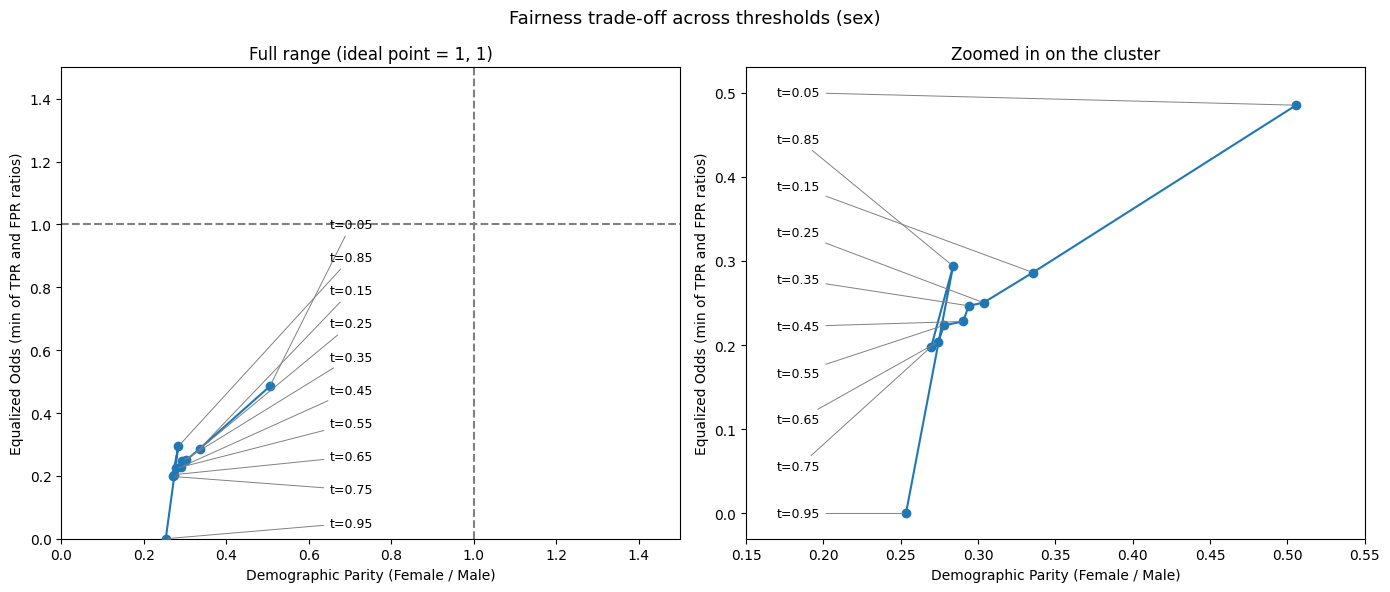

In [18]:
import matplotlib.pyplot as plt

pts = fair.dropna(subset=["DP", "EO"])

def draw_panel(ax, xlim, ylim, label_x, label_y_top, label_y_bottom, title):
    ax.plot(pts["DP"], pts["EO"], "o-", zorder=3)
    ax.axvline(1, ls="--", c="grey")
    ax.axhline(1, ls="--", c="grey")
    ordered = pts.sort_values("EO", ascending=False)
    label_ys = np.linspace(label_y_top, label_y_bottom, len(ordered))
    for (_, r), ly in zip(ordered.iterrows(), label_ys):
        ax.annotate(f"t={r['t']:.2f}", xy=(r["DP"], r["EO"]), xytext=(label_x, ly),
                    va="center", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.7))
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel("Demographic Parity (Female / Male)")
    ax.set_ylabel("Equalized Odds (min of TPR and FPR ratios)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_panel(axes[0], (0, 1.5), (0, 1.5), 0.65, 1.0, 0.05, "Full range (ideal point = 1, 1)")
draw_panel(axes[1], (0.15, 0.55), (-0.03, 0.53), 0.17, 0.50, 0.0, "Zoomed in on the cluster")
fig.suptitle("Fairness trade-off across thresholds (sex)", fontsize=13)
plt.tight_layout()
plt.savefig("fairness_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()